# 10 Shorter vectors with PCA
In notebook 09, HNSW found 97% of the exact top 10 in a fraction of a millisecond. Here I test one more idea: make the vectors **shorter** with PCA, so that they take less memory and the search has less to compute. PCA keeps the directions in which the products differ most and drops the rest (I use it with 256, 128 and 64 numbers instead of 512 or 384). I run every method on the shorter vectors, with the same rule as before, and compare the time, the memory and the recall@10 with the full vectors. Nothing here uses the 20 locked final products.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(root)  # the project reads data/archive.zip relative to the project folder
sys.path.insert(0, str(root / "experiments"))
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

results = root / "results"
base = json.loads((results / "ann_exact_baseline.json").read_text(encoding="utf-8"))
bench = json.loads((results / "ann_benchmark.json").read_text(encoding="utf-8"))
pca = json.loads((results / "ann_pca.json").read_text(encoding="utf-8"))
print("loaded the saved results")

loaded the saved results


## 1. How I did it
The rule is the same as in notebook 09, so the numbers can be compared directly:

| What | Rule |
|---|---|
| Test products | The same 1,000 random products (seed 2020), never a locked product and never one of my 30 development products |
| Time | Each product is searched 5 times and the fastest run is kept. The time shown is the median of the 1,000. One thread, one query at a time |
| Recall@10 | The average over the same 1,000 products: how many of the exact top 10 **on the full vectors** the method also found. So it shows what PCA and the index lose together |
| PCA | Trained on all the vectors, and keeps 256, 128 or 64 numbers. The shorter vectors are scaled to length 1 again, so that the dot product is still the cosine similarity |
| Methods | The same as before, on the shorter vectors: exact search (FAISS Flat), HNSW, IVF and Annoy, with the same settings |
| Extra cost | A query must first be turned into its short version with PCA. I timed that too (`projection_ms`) |

The code is `experiments/ann_pca.py`, and the results are in `results/ann_pca.json`.

## 2. Results: every method, with and without PCA
For each method and each length, I show the fastest setting whose recall is within half a point of that method's best. Without PCA, the rows are the ones from notebook 09 (the exact search and HNSW with `M` = 16, `efSearch` = 16).

In [2]:
def best(rows, method):
    group = [r for r in rows if r["index"] == method]
    top = max(r["recall_at_10"] for r in group)
    return min((r for r in group if r["recall_at_10"] >= top - 0.005), key=lambda r: r["ms_per_query"])

def setting(r):
    keys = ("M", "nlist", "n_trees", "efSearch", "nprobe", "search_k")
    return ", ".join(f"{k}={r[k]}" for k in keys if k in r)

rows = []
for space, info in pca["spaces"].items():
    exact = base["spaces"][space]
    hnsw = next(r for r in bench["spaces"][space]["indexes"] if r["index"] == "faiss_hnsw" and r["M"] == 16 and r["efSearch"] == 16)
    rows.append({"vectors": space, "numbers": info["dimensions"], "method": "exact search (NumPy)", "setting": "", "build (s)": 0.0, "memory (MB)": exact["memory_mb"], "time (ms)": exact["queries"]["random1000"]["one_query_median_ms"], "projection (ms)": None, "recall@10": 1.0})
    rows.append({"vectors": space, "numbers": info["dimensions"], "method": "faiss_hnsw", "setting": setting(hnsw), "build (s)": hnsw["build_seconds"], "memory (MB)": hnsw["index_mb"], "time (ms)": hnsw["ms_per_query"], "projection (ms)": None, "recall@10": hnsw["recall_at_10"]})
    for dims, block in info["by_dimensions"].items():
        for method in ("faiss_flat", "faiss_hnsw", "faiss_ivf", "annoy"):
            r = best(block["indexes"], method)
            rows.append({"vectors": space, "numbers": int(dims), "method": method + " + PCA", "setting": setting(r), "build (s)": r["build_seconds"], "memory (MB)": r["index_mb"], "time (ms)": r["ms_per_query"], "projection (ms)": block["projection_ms"], "recall@10": r["recall_at_10"]})
table = pd.DataFrame(rows)
for space in ("sentence", "picture"):
    print(f"--- {space} vectors ---")
    display(table[table["vectors"] == space].drop(columns="vectors").set_index(["numbers", "method"]))

--- sentence vectors ---


setting  build (s)  memory (MB)  time (ms)  projection (ms)  recall@10
numbers method                                                                                                          
384     exact search (NumPy)                                    0.00         45.3      0.850              NaN     1.0000
        faiss_hnsw                      M=16, efSearch=16       6.39         49.6      0.014              NaN     0.9727
256     faiss_flat + PCA                                        0.00         30.2      0.565           0.0097     0.8682
        faiss_hnsw + PCA                M=32, efSearch=16       5.26         38.2      0.015           0.0097     0.8645
        faiss_ivf + PCA              nlist=171, nprobe=32       0.11         30.6      0.119           0.0097     0.8605
        annoy + PCA           n_trees=100, search_k=22000       2.08         71.1      1.613           0.0097     0.8581
128     faiss_flat + PCA                                        0.00         15.1      0.278           0.0090     0.8269
        faiss_hnsw + PCA                M=32, efSearch=16       3.02         23.1      0.011           0.0090     0.8246
        faiss_ivf + PCA              nlist=171, nprobe=16       0.07         15.4      0.036           0.0090     0.8178
        annoy + PCA            n_trees=50, search_k=11000       0.76         36.2      0.644           0.0090     0.8179
64      faiss_flat + PCA                                        0.00          7.6      0.141           0.0079     0.7209
        faiss_hnsw + PCA                M=32, efSearch=16       2.49         15.6      0.009           0.0079     0.7189
        faiss_ivf + PCA              nlist=171, nprobe=16       0.06          7.8      0.020           0.0079     0.7141
        annoy + PCA            n_trees=50, search_k=11000       0.58         29.1      0.474           0.0079     0.7179

--- picture vectors ---


setting  build (s)  memory (MB)  time (ms)  projection (ms)  recall@10
numbers method                                                                                                         
512     exact search (NumPy)                                   0.00         60.1      1.500              NaN     1.0000
        faiss_hnsw                     M=16, efSearch=16       6.96         64.4      0.018              NaN     0.9735
256     faiss_flat + PCA                                       0.00         30.1      0.572           0.0105     0.7683
        faiss_hnsw + PCA               M=16, efSearch=16       4.46         34.3      0.013           0.0105     0.7649
        faiss_ivf + PCA             nlist=171, nprobe=16       0.11         30.5      0.064           0.0105     0.7655
        annoy + PCA           n_trees=50, search_k=11000       1.14         50.4      0.906           0.0105     0.7655
128     faiss_flat + PCA                                       0.00         15.0      0.278           0.0094     0.7080
        faiss_hnsw + PCA               M=16, efSearch=16       2.55         19.3      0.010           0.0094     0.7053
        faiss_ivf + PCA             nlist=171, nprobe=16       0.07         15.4      0.034           0.0094     0.7062
        annoy + PCA           n_trees=100, search_k=5500       1.26         54.9      0.376           0.0094     0.7049
64      faiss_flat + PCA                                       0.00          7.5      0.140           0.0083     0.6180
        faiss_hnsw + PCA               M=16, efSearch=16       2.19         11.8      0.008           0.0083     0.6159
        faiss_ivf + PCA             nlist=171, nprobe=16       0.06          7.8      0.020           0.0083     0.6166
        annoy + PCA            n_trees=50, search_k=2750       0.50         27.4      0.148           0.0083     0.6144

### What this shows
Memory and time go down as the vectors get shorter, but recall goes down much faster. For the picture vectors, 128 numbers find about 71% of the exact top 10, and 64 numbers find 62%. For the sentence vectors, 128 numbers find 82% to 83%, and 64 numbers find 72%. Every method ends up at nearly the same recall for a given length (the exact search, HNSW, IVF and Annoy are within about one point). So the loss comes from PCA itself, not from the index, and no index can win it back.

## 3. Where does the recall go?
The same numbers as a table of recall only: one row for each length and one column for each method. The first row is without PCA.

In [3]:
pivot_rows = []
for space, info in pca["spaces"].items():
    full = {"faiss_flat": 1.0, "faiss_hnsw": next(r for r in bench["spaces"][space]["indexes"] if r["index"] == "faiss_hnsw" and r["M"] == 16 and r["efSearch"] == 16)["recall_at_10"]}
    full_ivf = max(r["recall_at_10"] for r in bench["spaces"][space]["indexes"] if r["index"] == "faiss_ivf")
    full_annoy = max(r["recall_at_10"] for r in bench["spaces"][space]["indexes"] if r["index"] == "annoy")
    pivot_rows.append({"vectors": space, "numbers": f"{info['dimensions']} (no PCA)", "exact": 1.0, "HNSW": full["faiss_hnsw"], "IVF": full_ivf, "Annoy": full_annoy})
    for dims, block in info["by_dimensions"].items():
        pivot_rows.append({"vectors": space, "numbers": dims, "exact": best(block["indexes"], "faiss_flat")["recall_at_10"], "HNSW": best(block["indexes"], "faiss_hnsw")["recall_at_10"], "IVF": best(block["indexes"], "faiss_ivf")["recall_at_10"], "Annoy": best(block["indexes"], "annoy")["recall_at_10"]})
display(pd.DataFrame(pivot_rows).set_index(["vectors", "numbers"]).round(3))
print("recall@10 of the best setting of each method (no PCA: HNSW is M=16, efSearch=16; IVF and Annoy show their best setting)")

exact   HNSW    IVF  Annoy
vectors  numbers                                 
sentence 384 (no PCA)  1.000  0.973  0.991  0.982
         256           0.868  0.864  0.860  0.858
         128           0.827  0.825  0.818  0.818
         64            0.721  0.719  0.714  0.718
picture  512 (no PCA)  1.000  0.974  1.000  0.992
         256           0.768  0.765  0.766  0.766
         128           0.708  0.705  0.706  0.705
         64            0.618  0.616  0.617  0.614

recall@10 of the best setting of each method (no PCA: HNSW is M=16, efSearch=16; IVF and Annoy show their best setting)


### What this shows
Look along a row: without PCA the fast methods reach 97% to 100%, with PCA they all sit at the same lower level as the exact search. The exact search on the shortened vectors already loses that much, because some of the true neighbours are no longer neighbours once the vectors are cut.

## 4. Time and recall in one chart
Each dot is one setting. A circle is a method without PCA, and the other shapes are the shorter vectors. Up and to the left is better.

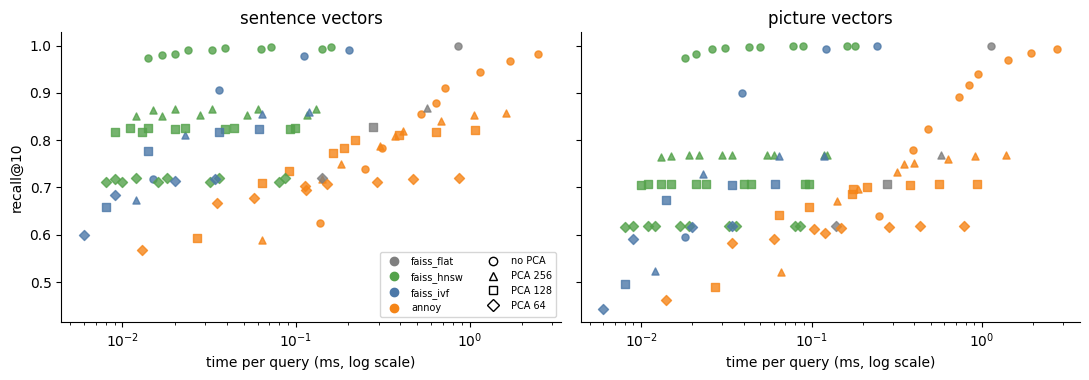

In [4]:
colours = {"faiss_flat": "#7f7f7f", "faiss_hnsw": "#54a24b", "faiss_ivf": "#4c78a8", "annoy": "#f58518"}
shapes = {0: "o", 256: "^", 128: "s", 64: "D"}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
for ax, space in zip(axes, ("sentence", "picture")):
    for r in bench["spaces"][space]["indexes"]:
        ax.scatter(r["ms_per_query"], r["recall_at_10"], color=colours[r["index"]], marker="o", s=26, alpha=0.8)
    for dims, block in pca["spaces"][space]["by_dimensions"].items():
        for r in block["indexes"]:
            ax.scatter(r["ms_per_query"], r["recall_at_10"], color=colours[r["index"]], marker=shapes[int(dims)], s=26, alpha=0.8)
    ax.set_xscale("log")
    ax.set_xlabel("time per query (ms, log scale)")
    ax.set_title(f"{space} vectors")
axes[0].set_ylabel("recall@10")
handles = [plt.Line2D([], [], marker="o", color=c, linestyle="", label=m) for m, c in colours.items()]
handles += [plt.Line2D([], [], marker=s, color="black", linestyle="", markerfacecolor="none", label="no PCA" if d == 0 else f"PCA {d}") for d, s in shapes.items()]
axes[0].legend(handles=handles, fontsize=7, loc="lower right", ncol=2)
plt.tight_layout()
plt.show()

### What this shows
The circles (no PCA) sit at the top of the chart. Every shorter version moves down: the shapes for 128 and 64 numbers are below 0.9 for every method. The shapes also move a little to the left, which means faster, but the gain is small compared with the recall that is lost. HNSW without PCA is already about as far left as the PCA versions.

## 5. Is the speed-up real? The cost of turning a query into a short vector
The time in the tables is the search only. With PCA, the query vector must first be projected to the short version. I timed that separately:

In [5]:
rows = []
for space, info in pca["spaces"].items():
    hnsw = next(r for r in bench["spaces"][space]["indexes"] if r["index"] == "faiss_hnsw" and r["M"] == 16 and r["efSearch"] == 16)
    rows.append({"vectors": space, "numbers": info["dimensions"], "HNSW search (ms)": hnsw["ms_per_query"], "projection (ms)": 0.0, "total (ms)": hnsw["ms_per_query"]})
    for dims, block in info["by_dimensions"].items():
        r = best(block["indexes"], "faiss_hnsw")
        rows.append({"vectors": space, "numbers": int(dims), "HNSW search (ms)": r["ms_per_query"], "projection (ms)": block["projection_ms"], "total (ms)": round(r["ms_per_query"] + block["projection_ms"], 4)})
display(pd.DataFrame(rows).set_index(["vectors", "numbers"]))

HNSW search (ms)  projection (ms)  total (ms)
vectors  numbers                                               
sentence 384                 0.014           0.0000      0.0140
         256                 0.015           0.0097      0.0247
         128                 0.011           0.0090      0.0200
         64                  0.009           0.0079      0.0169
picture  512                 0.018           0.0000      0.0180
         256                 0.013           0.0105      0.0235
         128                 0.010           0.0094      0.0194
         64                  0.008           0.0083      0.0163

### What this shows
Turning a query into its short vector costs about 0.008 to 0.011 ms, which is about as much as the HNSW search itself. So the total time with PCA is about the same as HNSW on the full vectors or higher. The only case that is a little lower is the picture vectors with 64 numbers (0.016 ms against 0.018 ms), and that one finds only 62% of the exact top 10. PCA mainly saves memory here.

## 6. Recorded in MLflow
Every setting on the shorter vectors is one run in the experiment `ann-pca`: 148 runs in all, with the same kind of record as in notebook 09, plus the projection time and a `pca` parameter. The runs tagged `headline = yes` are the two methods without PCA (the exact search and HNSW) and HNSW on the 256, 128 and 64 numbers. This is MLflow's comparison page for those ten runs, sentence vectors on the left and picture vectors on the right:

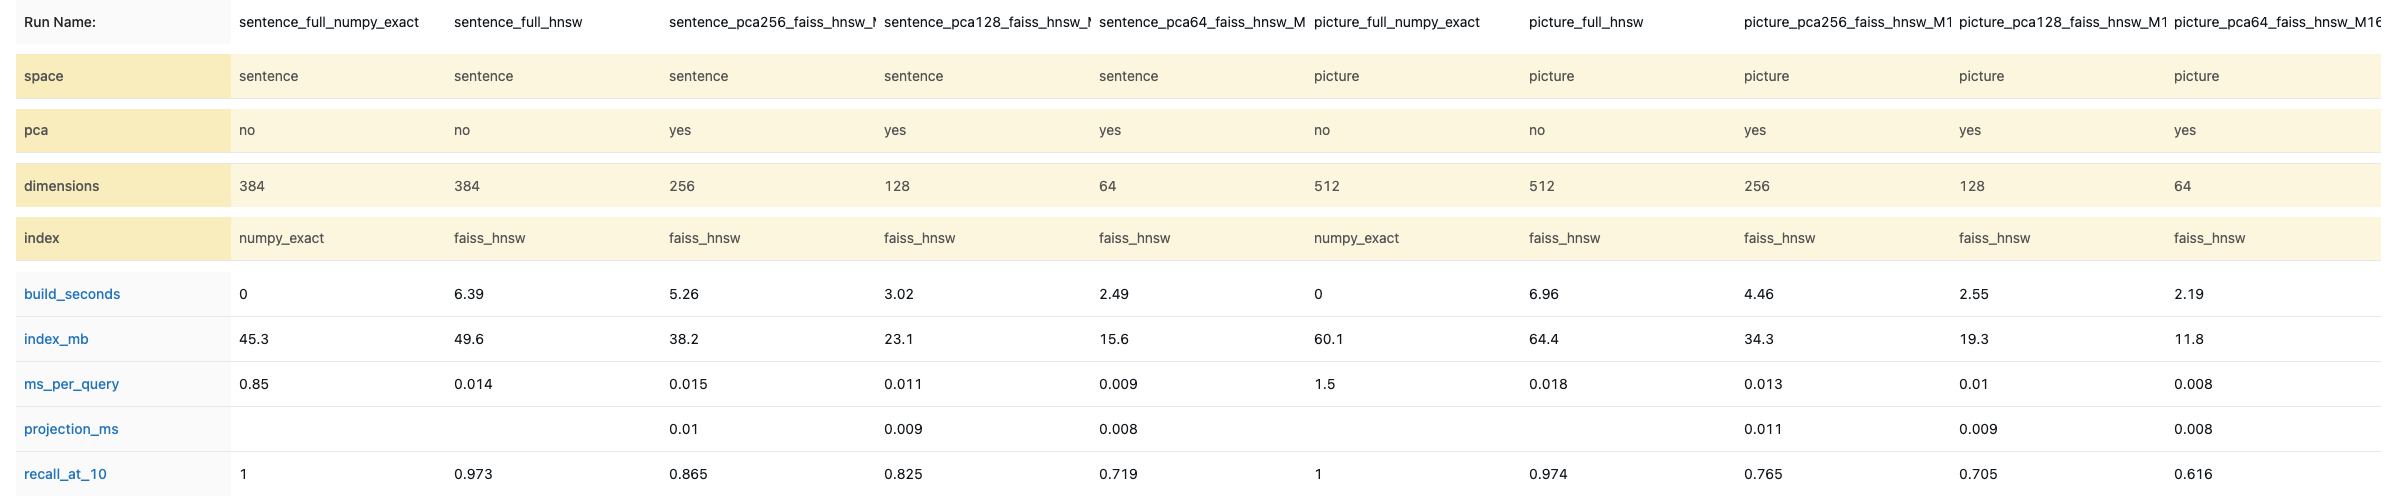

In [6]:
from IPython.display import Image

Image(filename=root / "evaluation" / "mlflow_ann_pca_runs.png", width=1000)

References: Jolliffe and Cadima, [Principal component analysis: a review and recent developments](https://doi.org/10.1098/rsta.2015.0202) (2016) (PCA); the search methods are the ones from notebook 09 (see its references).

## 7. Conclusion

**What I wanted to know:** can I make the vectors shorter with PCA, so that they take less memory and the search is faster, without losing much recall?

**What I did.** I trained PCA on all the vectors and kept 256, 128 or 64 numbers instead of 512 (pictures) or 384 (sentences). I ran the exact search, FAISS HNSW, FAISS IVF and Annoy on the shorter vectors, with the same rule as in notebook 09: the same 1,000 random products (seed 2020, never a locked product), each searched 5 times with the fastest run kept, the median time, one thread. Recall@10 is measured against the exact top 10 on the full vectors, so it shows what PCA and the index lose together. I also timed the extra step of turning a query into its short version, and I recorded every setting in MLflow (experiment `ann-pca`, 148 runs).

| Picture vectors | Time per query | Memory | Recall@10 |
|---|---|---|---|
| Exact search, 512 numbers (no PCA) | 1.5 ms | 60.1 MB | 100% |
| HNSW, 512 numbers (no PCA) | 0.018 ms | 64.4 MB | 97% |
| HNSW + PCA, 256 numbers | 0.013 ms | 34.3 MB | 76% |
| HNSW + PCA, 128 numbers | 0.010 ms | 19.3 MB | 71% |
| HNSW + PCA, 64 numbers | 0.008 ms | 11.8 MB | 62% |

| Sentence vectors | Time per query | Memory | Recall@10 |
|---|---|---|---|
| Exact search, 384 numbers (no PCA) | 0.85 ms | 45.3 MB | 100% |
| HNSW, 384 numbers (no PCA) | 0.014 ms | 49.6 MB | 97% |
| HNSW + PCA, 256 numbers | 0.015 ms | 38.2 MB | 86% |
| HNSW + PCA, 128 numbers | 0.011 ms | 23.1 MB | 82% |
| HNSW + PCA, 64 numbers | 0.009 ms | 15.6 MB | 72% |

**What I found**

- PCA makes the vectors and the index smaller: with 128 numbers the picture index goes from 64 MB to 19 MB.
- The recall drops a lot. With 128 numbers, the picture vectors find 71% of the exact top 10 and the sentence vectors 82%, against 97% for HNSW on the full vectors.
- The loss comes from PCA itself. For a given length, the exact search, HNSW, IVF and Annoy all end up within about one point of each other, so a better index does not win it back.
- The speed-up is small and not real. Turning a query into its short version takes about 0.009 ms, which is about as much as the HNSW search itself (0.010 to 0.018 ms). With that step, the total is about the same as HNSW on the full vectors or higher (the only case a little lower, 0.016 ms against 0.018 ms, is the picture vectors with 64 numbers, at 62% recall).

**Decision.** I drop PCA. The search keeps the full vectors with HNSW, which finds 97% of the exact top 10 in 0.014 to 0.018 ms. At my size, memory is not a problem (about 50 to 65 MB per index).

**What I can't say yet**

- I tested only about 29,500 products. For millions of products, the memory saving of PCA could matter, and a milder cut (more than 256 numbers) or a better trained reduction could be worth testing. I did not test that.
- I trained PCA on all the vectors, including the test products. This is fine for a comparison of methods, but a real system would train it on a separate sample.
- The timings are from one laptop, one thread, one query at a time.

**What I do next.** I will make the service stronger (checks on the input and proper error codes), and then add caching, Kubernetes and the weights page.